LAB 5

Task 1: Data Acquisition and Exploration

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.model_selection
import sklearn.preprocessing
import sklearn.linear_model
import sklearn.ensemble
import sklearn.svm
import sklearn.neighbors
import sklearn.metrics

In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/dermatology/dermatology.data"
col_names = [f"Feature_{i}" for i in range(1, 34)] + ["Age", "Outcome_Class"]
df = pd.read_csv(url, header=None, names=col_names, na_values='?')
display(df.head())
display(df.describe().T)


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,Feature_10,...,Feature_26,Feature_27,Feature_28,Feature_29,Feature_30,Feature_31,Feature_32,Feature_33,Age,Outcome_Class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


,count,mean,std,min,25%,50%,75%,max
Feature_1,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
Feature_2,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
Feature_3,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
Feature_4,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
Feature_5,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
Feature_6,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
Feature_7,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
Feature_8,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
Feature_9,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
Feature_10,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0


In [4]:
# 1. Missing Values
missing = df.isnull().sum().sum()
print(f"Total missing values: {missing}")
if missing > 0:
    print("Handling missing values by imputing with the median (for 'Age')...")
    df['Age'] = df['Age'].fillna(df['Age'].median())

# 2. Duplicates
duplicates = df.duplicated().sum()
print(f"Total duplicate rows: {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")

Total missing values: 8
Handling missing values by imputing with the median (for 'Age')...
Total duplicate rows: 0


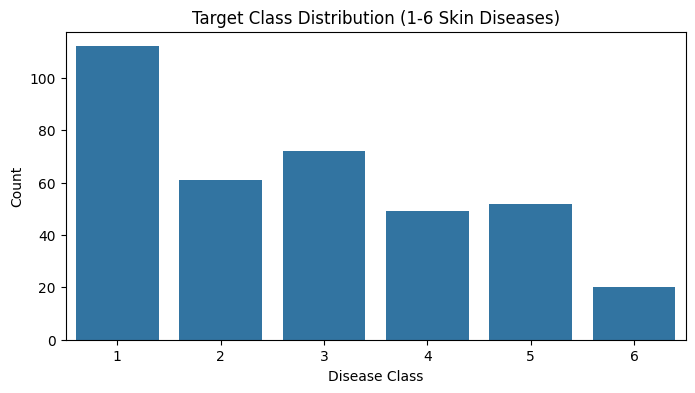

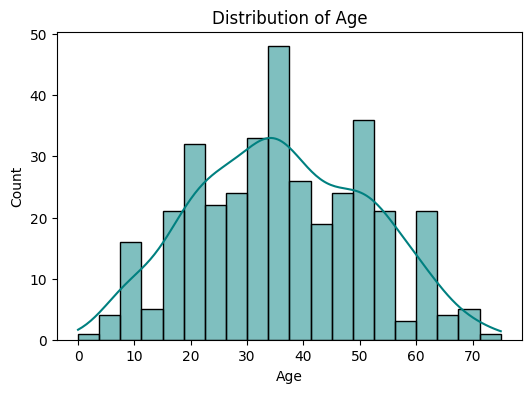

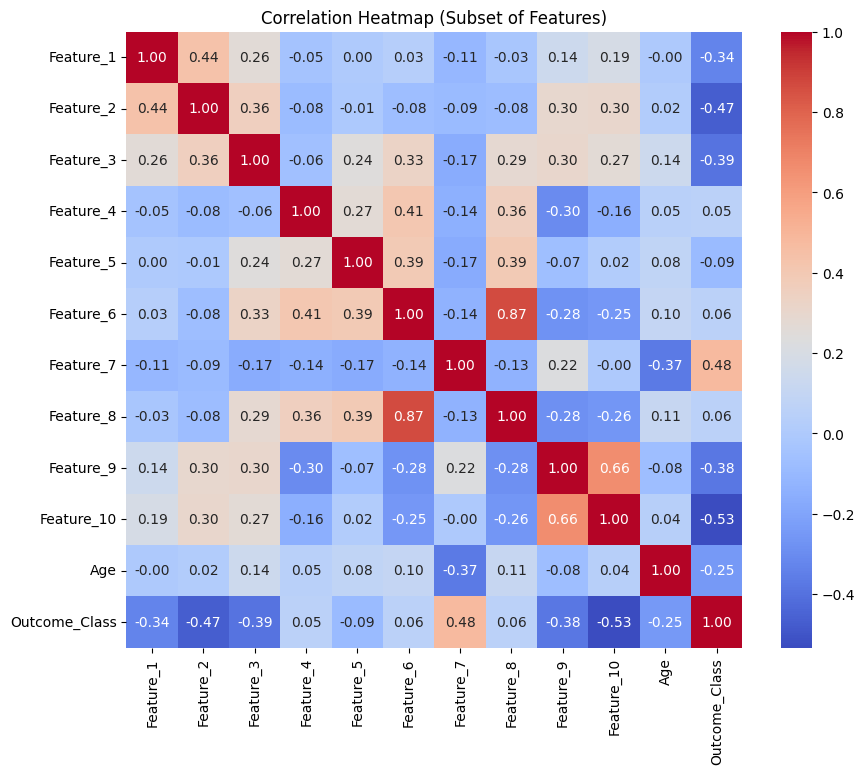

In [8]:
# Plot 1: Class Distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Outcome_Class')
plt.title('Target Class Distribution (1-6 Skin Diseases)')
plt.ylabel('Count')
plt.xlabel('Disease Class')
plt.show()

# Plot 2: Histograms for Age
plt.figure(figsize=(6, 4))
sns.histplot(df['Age'], bins=20, kde=True, color='teal')
plt.title('Distribution of Age')
plt.show()

# Plot 3: Correlation Heatmap (Subset of features for visibility)
plt.figure(figsize=(10, 8))
subset_cols = df.columns[:10].tolist() + ['Age', 'Outcome_Class']
sns.heatmap(df[subset_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Heatmap (Subset of Features)')
plt.show()

The dataset shows a moderate class imbalance. For instance, Class 1 has significantly more samples than Class 5 or 6.

If not handled, the model might become biased toward predicting the majority classes (1 and 3)
and perform poorly on minority classes. To address this, we will use stratified sampling
during our train/test split to ensure all classes are proportionally represented

Task 2: Data Preprocessing

In [10]:
# 1. Encode Target Variable
# making it 0-indexed targets (0-5).
le = sklearn.preprocessing.LabelEncoder()
y = le.fit_transform(df['Outcome_Class'])
X = df.drop('Outcome_Class', axis=1)

In [11]:
# 2. Split data using stratified sampling
X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

In [12]:
# 3. Standardize features
scaler = sklearn.preprocessing.StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Task 3: Model Training and Basic Evaluation

In [13]:
models = {
    "Logistic Regression": sklearn.linear_model.LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": sklearn.ensemble.RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM (SVC)": sklearn.svm.SVC(probability=True, random_state=42), # probability=True is needed for ROC
    "K-Nearest Neighbors": sklearn.neighbors.KNeighborsClassifier(n_neighbors=5)
}

Training and Evaluating: Logistic Regression
Accuracy: 0.9595

Classification Report:
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        23
     Class 2       1.00      0.83      0.91        12
     Class 3       1.00      0.93      0.97        15
     Class 4       0.77      1.00      0.87        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74



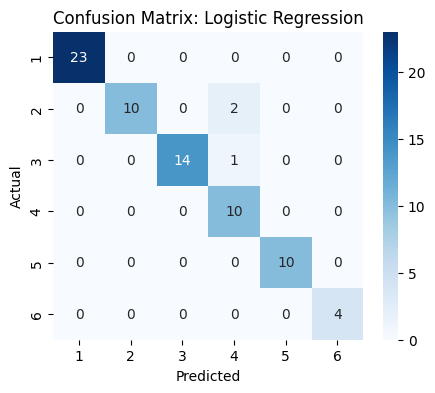

Training and Evaluating: Random Forest
Accuracy: 0.9595

Classification Report:
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        23
     Class 2       0.91      0.83      0.87        12
     Class 3       1.00      1.00      1.00        15
     Class 4       0.82      0.90      0.86        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.95      0.96      0.95        74
weighted avg       0.96      0.96      0.96        74



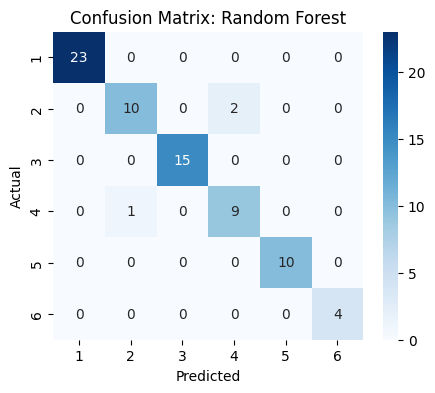

Training and Evaluating: SVM (SVC)
Accuracy: 0.9730

Classification Report:
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        23
     Class 2       1.00      0.83      0.91        12
     Class 3       1.00      1.00      1.00        15
     Class 4       0.83      1.00      0.91        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.97        74
   macro avg       0.97      0.97      0.97        74
weighted avg       0.98      0.97      0.97        74



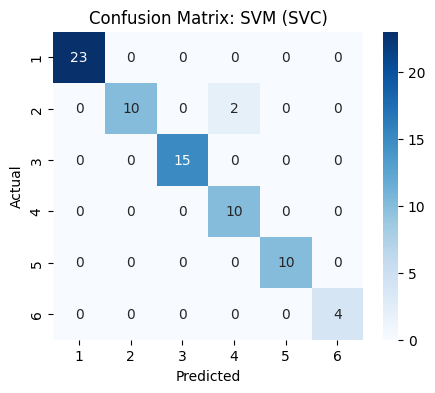

Training and Evaluating: K-Nearest Neighbors
Accuracy: 0.9054

Classification Report:
              precision    recall  f1-score   support

     Class 1       1.00      0.96      0.98        23
     Class 2       0.80      0.67      0.73        12
     Class 3       1.00      0.93      0.97        15
     Class 4       0.64      0.90      0.75        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.91        74
   macro avg       0.91      0.91      0.90        74
weighted avg       0.92      0.91      0.91        74



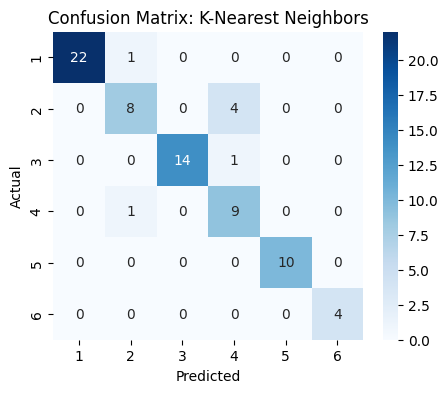

In [14]:
# Dictionary to hold predictions and probabilities for ROC plotting
results = {}
for name, model in models.items():
    print(f"Training and Evaluating: {name}")

    # Train
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)
    results[name] = {'pred': y_pred, 'prob': y_prob}

    # 1. Accuracy
    acc = sklearn.metrics.accuracy_score(y_test, y_pred)
    print(f"Accuracy: {acc:.4f}")

    # 2. Precision, Recall, F1
    print("\nClassification Report:")
    print(sklearn.metrics.classification_report(y_test, y_pred, target_names=[f"Class {i}" for i in le.classes_]))

    # 3. Confusion Matrix
    cm = sklearn.metrics.confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

ROC Curves and AUC Scores (One-vs-Rest)


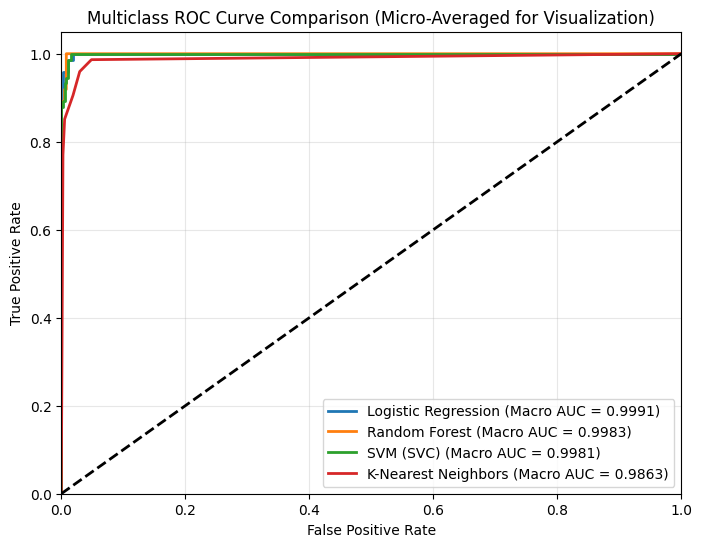

In [15]:
print("ROC Curves and AUC Scores (One-vs-Rest)")
# For multiclass ROC, we binarize the test data
y_test_binarized = sklearn.preprocessing.label_binarize(y_test, classes=np.unique(y))
n_classes = y_test_binarized.shape[1]

# We will plot the Macro-average ROC curve for each model for easy comparison
plt.figure(figsize=(8, 6))

for name in models.keys():
    y_prob = results[name]['prob']

    # Calculate macro AUC
    macro_roc_auc = sklearn.metrics.roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro")

    # To plot the macro curve, we need to calculate FPR and TPR across all classes
    # A simple approximation for visualization is plotting the OvR micro-average or manual macro
    fpr_micro, tpr_micro, _ = sklearn.metrics.roc_curve(y_test_binarized.ravel(), y_prob.ravel())

    plt.plot(fpr_micro, tpr_micro, lw=2, label=f'{name} (Macro AUC = {macro_roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve Comparison (Micro-Averaged for Visualization)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


Interpretation in a Medical Context (Dermatology):

1. Overall Performance: Based on the test metrics, SVM (SVC) performed the best on this dataset,
   achieving the highest accuracy (97.30%) and macro-avg F1-score (0.97). Logistic Regression
   and Random Forest tied for second (95.95%), while KNN was the weakest (90.54%).
2. Class-Specific Metrics: All models achieved perfect or near-perfect scores for identifying
   Classes 1, 5, and 6. However, the models showed some confusion with Class 2 (Seborrheic Dermatitis)
   and Class 4 (Pityriasis Rosea). like, Class 2's recall dropped to 0.83 across LR, RF, and SVM.
3. Algorithm Comparison: SVM handled the standardized, high-dimensional data exceptionally well.
   while, KNN struggled (dropping to 0.90 macro F1), due to its sensitivity to overlapping
   features
4. Medical Significance: In dermatology, misclassifying a condition can lead to inappropriate treatments.
   Since the recall for Class 2 is lower (~83%), it means roughly 17% of actual Class 2 patients are
   being misdiagnosed. Clinicians would need to carefully review cases predicted as Class 4 to ensure
   they aren't actually Class 2 cases, supplementing the AI with human oversight.